# INSTITUTO Univeridad Autonoma del Estado de Mexico Centro Universitario UAEM Zumpango
**Asignatura:** Investigación de Operaciones
**Práctica 4:** Programación Lineal
**Integrantes:** 
- Alexis Yahir Alvarez Leon
- Ariadna Abigail Alanis Estrada, Jose Antonio Roriguez Estudillo
**Fecha:** 15/11/26

## 1. Descripción y Planteamiento del Problema (Enfoque TI)
Una empresa de desarrollo de software tiene dos líneas de negocio: **Desarrollo de Apps Web** y **Desarrollo de Apps Móviles**. 

La empresa quiere determinar cuántos proyectos de cada tipo debe aceptar al mes para **maximizar sus ganancias**. Sin embargo, tienen limitaciones de recursos:
- Cuentan con un equipo de programadores que trabajan máximo **80 horas al mes**.
- Cuentan con un equipo de diseñadores UX/UI que trabajan máximo **100 horas al mes**.

**Datos:**
- Una App Web genera **$4,000** de ganancia, requiere **4 horas** de programación y **2 horas** de diseño.
- Una App Móvil genera **$3,000** de ganancia, requiere **2 horas** de programación y **4 horas** de diseño.

## 2. Formulación Matemática
- **Variables de Decisión:**
  - \(x_1\): Cantidad de Apps Web a desarrollar.
  - \(x_2\): Cantidad de Apps Móviles a desarrollar.

- **Función Objetivo (Maximizar ganancias):**
  \[
Max Z = 4000x_1 + 3000x_2
\]

- **Restricciones:**
  - Horas de programación: \(4x_1 + 2x_2 \leq 80\)
  - Horas de diseño: \(2x_1 + 4x_2 \leq 100\)
  - No negatividad: \(x_1 \geq 0, x_2 \geq 0\)

## 3. Graficación de Restricciones
A continuación, graficaremos las líneas de restricción para visualizar la **región factible** (el área donde se cumplen todas las condiciones).

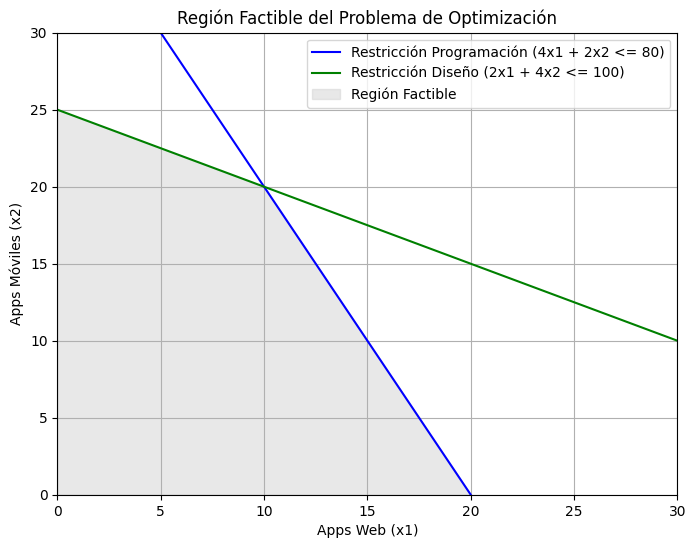

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

# Definir el rango para x1 y x2
x = np.linspace(0, 30, 400)

# Ecuaciones de las restricciones (despejando x2)
# Programación: 4x1 + 2x2 = 80 -> x2 = (80 - 4x1) / 2
y_prog = (80 - 4*x) / 2

# Diseño: 2x1 + 4x2 = 100 -> x2 = (100 - 2x1) / 4
y_diseño = (100 - 2*x) / 4

plt.figure(figsize=(8, 6))
plt.plot(x, y_prog, label='Restricción Programación (4x1 + 2x2 <= 80)', color='blue')
plt.plot(x, y_diseño, label='Restricción Diseño (2x1 + 4x2 <= 100)', color='green')

# Sombrear la región factible
plt.fill_between(x, np.minimum(y_prog, y_diseño), where=(np.minimum(y_prog, y_diseño) >= 0), color='lightgray', alpha=0.5, label='Región Factible')

plt.xlim(0, 30)
plt.ylim(0, 30)
plt.xlabel('Apps Web (x1)')
plt.ylabel('Apps Móviles (x2)')
plt.title('Región Factible del Problema de Optimización')
plt.legend()
plt.grid(True)
plt.show()

## 4. Resolución del Modelo con Python (SciPy)
Utilizaremos la función `linprog` de la librería `SciPy`. 
*Nota importante:* `linprog` está diseñada para **minimizar**, así que para maximizar nuestras ganancias, multiplicaremos la función objetivo por -1.

In [ ]:
# Coeficientes de la función objetivo (negativos porque SciPy minimiza)
c = [-4000, -3000]

# Matriz de coeficientes de las restricciones
A = [
    [4, 2],  # Programación
    [2, 4]   # Diseño
]

# Límites de las restricciones (lado derecho)
b = [80, 100]

# Límites de las variables (No negatividad)
x0_bounds = (0, None)
x1_bounds = (0, None)

# Resolver el problema
resultado = linprog(c, A_ub=A, b_ub=b, bounds=[x0_bounds, x1_bounds], method='highs')

print("--- RESULTADOS DE LA OPTIMIZACIÓN ---")
print(f"Estado: {resultado.message}")
print(f"Apps Web a desarrollar (x1): {resultado.x[0]:.2f}")
print(f"Apps Móviles a desarrollar (x2): {resultado.x[1]:.2f}")

# El resultado de la función objetivo viene en negativo, lo pasamos a positivo
ganancia_maxima = -resultado.fun
print(f" GANANCIA MÁXIMA: ${ganancia_maxima:,.2f}")

--- RESULTADOS DE LA OPTIMIZACIÓN ---
Estado: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Apps Web a desarrollar (x1): 10.00
Apps Móviles a desarrollar (x2): 20.00
💰 GANANCIA MÁXIMA: $100,000.00


## 5. Visualización de la Solución Óptima
Mostramos el punto exacto dentro de la región factible que nos da la máxima ganancia.

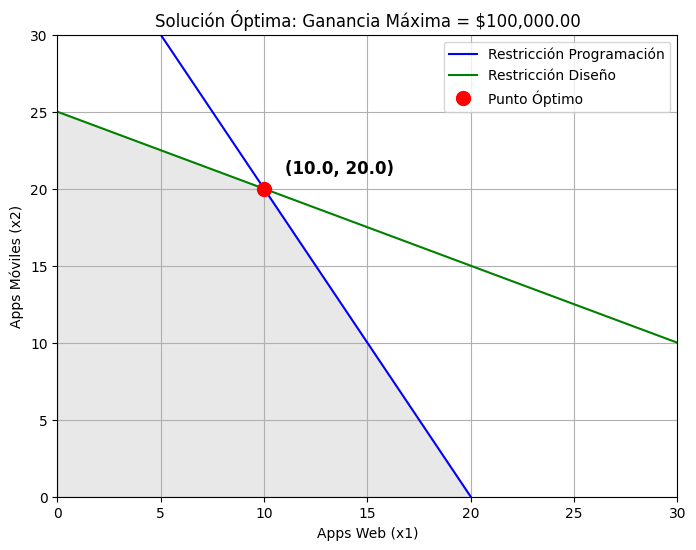

In [3]:
plt.figure(figsize=(8, 6))
plt.plot(x, y_prog, label='Restricción Programación', color='blue')
plt.plot(x, y_diseño, label='Restricción Diseño', color='green')
plt.fill_between(x, np.minimum(y_prog, y_diseño), where=(np.minimum(y_prog, y_diseño) >= 0), color='lightgray', alpha=0.5)

# Graficar el punto óptimo
plt.plot(resultado.x[0], resultado.x[1], 'ro', markersize=10, label='Punto Óptimo')
plt.text(resultado.x[0] + 1, resultado.x[1] + 1, f'({resultado.x[0]:.1f}, {resultado.x[1]:.1f})', fontsize=12, fontweight='bold')

plt.xlim(0, 30)
plt.ylim(0, 30)
plt.xlabel('Apps Web (x1)')
plt.ylabel('Apps Móviles (x2)')
plt.title(f'Solución Óptima: Ganancia Máxima = ${ganancia_maxima:,.2f}')
plt.legend()
plt.grid(True)
plt.show()

## 6. Interpretación de Resultados
El modelo de programación lineal determinó que la empresa debe desarrollar **10 Apps Web y 20 Apps Móviles** al mes para obtener una ganancia máxima de **$100,000**. 
Al evaluar las restricciones, nos damos cuenta de que los recursos están totalmente optimizados (las restricciones están activas en el punto óptimo, es decir, se usan las 80 horas de programación y las 100 horas de diseño). Cualquier otra combinación dentro de la región factible generará menos dinero.

## 7. Conclusiones
**Ariadna Abigail:**
La gráfica de la región factible aclara mucho el problema. Ubicar el punto exacto de máxima ganancia resulta muy útil para tomar decisiones sobre qué proyectos aceptar en la empresa.

**Jose Antonio**:
Resolver las restricciones con SciPy demuestra cómo un modelo matemático puede indicar exactamente cuántos proyectos hacer para no saturar al personal de TI y maximizar las ganancias.



**Alexis:** Aprendí a traducir un problema de negocio a un modelo matemático de optimización y a resolverlo con `SciPy`. Ver la solución en la gráfica me ayudó a entender por qué el óptimo casi siempre ocurre en las intersecciones (vértices) de las restricciones.